In [ ]:
from google.colab import files

# Prompts you to upload the file from your local machine
uploaded = files.upload()

# Get the uploaded CSV filename automatically
csv_file_path = list(uploaded.keys())[0]
df = pd.read_csv(csv_file_path)

Saving streaming_content_trends.csv to streaming_content_trends (2).csv


Dataset Shape: (988, 14)

First 5 rows:
  search_category media_type       id                      title  \
0         popular      movie   969681  Spider-Man: Brand New Day   
1         popular      movie  1368337                The Odyssey   
2         popular      movie  1288445                     Mutiny   
3         popular      movie  1084244                Toy Story 5   
4         popular      movie  1323244              Rage of Stars   

  original_language                                genres release_date  \
0                en    Science Fiction, Action, Adventure   2026-07-29   
1                en            Adventure, Action, Fantasy   2026-07-15   
2                en                      Action, Thriller   2026-08-19   
3                en  Animation, Family, Comedy, Adventure   2026-06-17   
4                en     Action, Science Fiction, Thriller   2026-08-06   

   popularity  vote_average  vote_count origin_country  \
0   1657.2333         7.900        2098         

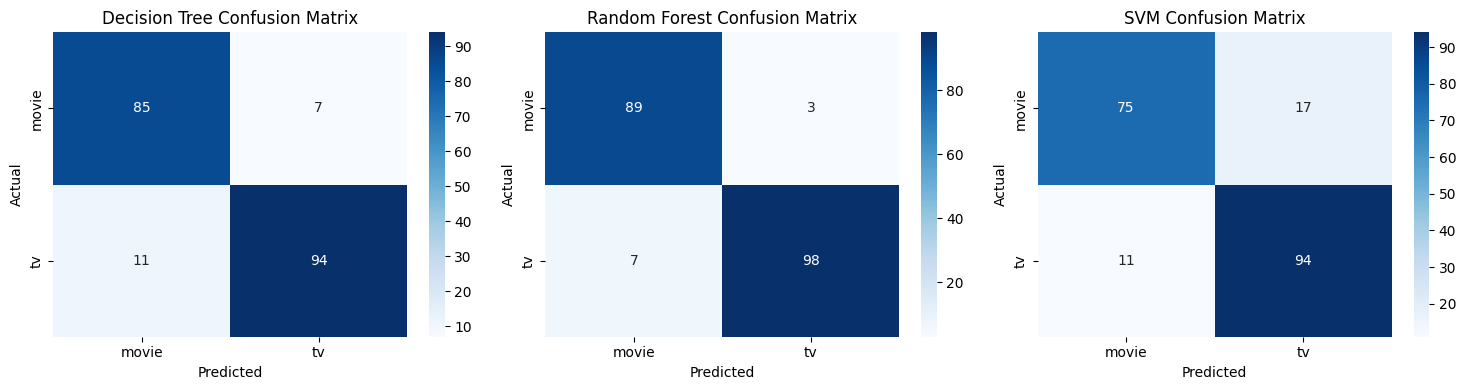


             MODEL COMPARISON
           Model  Accuracy  Precision    Recall  F1 Score
0  Decision Tree  0.908629   0.909549  0.908629  0.908714
1  Random Forest  0.949239   0.950116  0.949239  0.949286
2            SVM  0.857868   0.858637  0.857868  0.857447


In [ ]:
# ==========================================
# STREAMING CONTENT CLASSIFICATION
# Decision Tree, Random Forest and SVM
# Target: media_type (movie vs tv)
# ==========================================

import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# ==========================================
# 1. LOAD DATASET
# ==========================================

# Auto-detect path in Google Colab environment or use default filename
if "csv_file_path" in globals() and os.path.exists(csv_file_path):
    file_path = csv_file_path
elif "path" in globals() and os.path.exists(path):
    file_path = path
else:
    file_path = "streaming_content_trends.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


# ==========================================
# 2. FEATURE ENGINEERING & PREPROCESSING
# ==========================================

# Drop rows missing crucial modeling features
df = df.dropna(subset=["release_year", "genres", "media_type"]).copy()

# Extract primary genre from multi-genre string
df["primary_genre"] = df["genres"].apply(
    lambda x: str(x).split(",")[0].strip()
)

# Select features for classification
features = [
    "search_category",
    "original_language",
    "primary_genre",
    "vote_average",
    "vote_count",
    "popularity",
    "release_year",
    "is_recent",
]

X = df[features].copy()
y = df["media_type"]


# ==========================================
# 3. ENCODE CATEGORICAL DATA
# ==========================================

le = LabelEncoder()

# Encode predictor categorical variables
for column in X.select_dtypes(include=["object", "bool"]).columns:
    X[column] = le.fit_transform(X[column].astype(str))

# Encode target class labels
y_encoder = LabelEncoder()
y = y_encoder.fit_transform(y)


# ==========================================
# 4. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ==========================================
# 5. DECISION TREE
# ==========================================

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, average="weighted")
dt_recall = recall_score(y_test, dt_pred, average="weighted")
dt_f1 = f1_score(y_test, dt_pred, average="weighted")

dt_cm = confusion_matrix(y_test, dt_pred)


# ==========================================
# 6. RANDOM FOREST
# ==========================================

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, average="weighted")
rf_recall = recall_score(y_test, rf_pred, average="weighted")
rf_f1 = f1_score(y_test, rf_pred, average="weighted")

rf_cm = confusion_matrix(y_test, rf_pred)


# ==========================================
# 7. SUPPORT VECTOR MACHINE
# ==========================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC(kernel="rbf", random_state=42)
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, average="weighted")
svm_recall = recall_score(y_test, svm_pred, average="weighted")
svm_f1 = f1_score(y_test, svm_pred, average="weighted")

svm_cm = confusion_matrix(y_test, svm_pred)


# ==========================================
# 8. DISPLAY RESULTS
# ==========================================

print("\n==========================================")
print("           MODEL RESULTS")
print("==========================================")

print("\nDECISION TREE")
print("-------------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)
print("\nConfusion Matrix:\n", dt_cm)

print("\nRANDOM FOREST")
print("-------------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("\nConfusion Matrix:\n", rf_cm)

print("\nSUPPORT VECTOR MACHINE")
print("-------------------------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)
print("\nConfusion Matrix:\n", svm_cm)


# ==========================================
# 9. CLASSIFICATION REPORTS
# ==========================================

target_names = [str(cls) for cls in y_encoder.classes_]

print("\n==========================================")
print("       CLASSIFICATION REPORTS")
print("==========================================")

print("\nDECISION TREE:")
print(classification_report(y_test, dt_pred, target_names=target_names))

print("\nRANDOM FOREST:")
print(classification_report(y_test, rf_pred, target_names=target_names))

print("\nSUPPORT VECTOR MACHINE:")
print(classification_report(y_test, svm_pred, target_names=target_names))


# ==========================================
# 10. CONFUSION MATRICES PLOTS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[0],
)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[1],
)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[2],
)
axes[2].set_title("SVM Confusion Matrix")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()


# ==========================================
# 11. MODEL COMPARISON
# ==========================================

results = pd.DataFrame(
    {
        "Model": ["Decision Tree", "Random Forest", "SVM"],
        "Accuracy": [dt_accuracy, rf_accuracy, svm_accuracy],
        "Precision": [dt_precision, rf_precision, svm_precision],
        "Recall": [dt_recall, rf_recall, svm_recall],
        "F1 Score": [dt_f1, rf_f1, svm_f1],
    }
)

print("\n==========================================")
print("             MODEL COMPARISON")
print("==========================================")
print(results)